# REAL-CV-4. Виртуальный коуч для единоборств

**Спринт IV · Skillfactory · сравнение повторения удара ногой**

Сфера применения — разбор сходства движений в единоборствах. По двум предоставленным
видео извлекаем позы спортсменов, сопоставляем кадры и вычисляем **косинусное расстояние**
и **взвешенное L1-расстояние**. Показываем найденные скелеты и метрики на видео.

Задание прочитано из `Course _ Skillfactory_2.mhtml`; файл
`Course _ Skillfactory_1.mhtml` разрешает использовать модель предыдущих спринтов.
Материал `другие модели.mhtml` рассмотрен как обзор альтернатив. Здесь используется
Keypoint R-CNN: переобучение и замена модели не требуются.

## Краткий результат

Сохранённый запуск: **120/120 пригодных пар** полных роликов при линейной нормализации времени. Среднее **косинусное расстояние — 0.001987**, **взвешенное L1 — 51.357 px** референса.

Контроль без изменения темпа: **90/90 пар** общих первых 3 с, **L1 — 30.438 px**. Оценки относятся к разным временным сопоставлениям; временной порядок одинаков, совпадение фаз удара не гарантировано.

В основном режиме аффинное совмещение включало отражение в **75 парах**. Поэтому результат описывает сходство после свободной геометрической подгонки, а не качество техники. В разделе 6 доступны оба видео сравнения.

## 1. Задача и метод

| Этап задания | Решение |
| :--- | :--- |
| Выбрать сферу применения | Сравнение повторения удара ногой в единоборствах |
| Выбрать референс | Предоставленный `reference_video.mp4` целиком |
| Записать повторение | Предоставленный пользователем `my.mp4` целиком |
| Загрузить и предобработать | Декодирование, BGR → RGB, проверка времени, выбор спортсмена |
| Сравнить движения | Два временных сопоставления, аффинное совмещение, обе метрики |

### Основные допущения

- Референс длится 3 с, повторение — 4 с. **Основной режим** сопоставляет одинаковые
  доли длительности: начало с началом, конец с концом. Это линейная нормализация
  времени, а не определение реальных фаз удара. Разные паузы остаются источником ошибки.
- **Контрольный режим** сравнивает одинаковое прошедшее время в общих первых 3 с,
  без изменения темпа; последняя секунда `my.mp4` в нём не участвует.
- Временной сдвиг, перестановка левых/правых суставов и нелинейное растяжение времени
  не подбираются по метрике. Пространственное аффинное совмещение допускает отражение.
- На референсе слева расположен манекен. Человека выбираем среди детекций с центром
  рамки правее 40% ширины кадра: эта граница сохраняет спортсмена при приземлении.
  Изображение при этом **не обрезаем**, чтобы сохранить
  вытянутую ногу. Для `my.mp4` используем весь кадр. Из подходящих детекций берём
  максимальный score. Это правило подходит данным роликам, а не произвольной сцене.
- Метрики описывают сходство **2D-поз**. Ракурс, одежда, перекрытия и ошибки модели
  влияют на результат; оценка не является проверкой спортивной техники.

## Запуск в составе проекта

Это сохранённый учебный этап. Основной пример финальной версии находится в `examples/01_video_comparison.ipynb`.

Установите общие зависимости по [README проекта](../../../README.md) и выберите Python из окружения проекта в VS Code/Jupyter. Выполните **Restart Kernel → Run All**. Отдельное окружение для этого спринта не нужно.

Входные видео находятся в общей папке `data/` в корне проекта. Рабочей папкой ядра может быть папка этого ноутбука или корень `PROJECT_EASY-MOTION`; при другой рабочей папке укажите `PROJECT_DIR` явно. Результаты повторного запуска создаются в локальной подпапке `outputs/`. Она исключена из Git, а графики и таблицы сохранены в самом ноутбуке.

При первом запуске загружаются официальные веса COCO_V1. Материалы курса в MHTML не нужны для выполнения и в архив не включены. Для экспорта MP4 нужен FFmpeg в PATH. Ноутбук содержит встроенное видео; GitHub может не воспроизводить его, поэтому для просмотра видео откройте ноутбук локально. `USE_CACHE = False` включает повторный расчёт поз без локального кэша.

In [1]:
from pathlib import Path
from time import perf_counter
import csv
import hashlib
import json
import platform
import shutil
import subprocess

import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import torch
import torchvision
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Markdown, Video, display
from torchvision import transforms as T
from torchvision.models.detection import (
    KeypointRCNN_ResNet50_FPN_Weights, keypointrcnn_resnet50_fpn,
)

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 14, "axes.spines.top": False, "axes.spines.right": False,
})
COLORS = {"reference": "#2467C8", "input": "#D46D1F", "neutral": "#6B7280"}

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "REAL_CV_4_Martial_Arts_Coach.ipynb").is_file():
    PROJECT_DIR = PROJECT_DIR / "examples" / "sprints" / "sprint_4"
# Эти же видео используются основным примером проекта.
DATA_DIR = PROJECT_DIR.parents[2] / "data"
REFERENCE_PATH = DATA_DIR / "reference_video.mp4"
INPUT_PATH = DATA_DIR / "my.mp4"
OUTPUT_DIR = PROJECT_DIR / "outputs"
ANALYSIS_FPS = 30.0
SELECTION_X_RANGE = {"reference": (0.40, 1.00), "input": (0.00, 1.00)}
CONF_THRESHOLD = 0.9
KEYPOINT_THRESHOLD = 2.0
MIN_COMMON_KEYPOINTS = 6
USE_CACHE = True
CACHE_SCHEMA = "real-cv4-keypoints-v1"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for path in (REFERENCE_PATH, INPUT_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Не найден {path}. Проверьте PROJECT_DIR.")
OUTPUT_DIR.mkdir(exist_ok=True)

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
torch.backends.cudnn.benchmark = False
versions = {
    "python": platform.python_version(), "torch": torch.__version__,
    "torchvision": torchvision.__version__, "numpy": np.__version__,
    "opencv": cv2.__version__, "matplotlib": matplotlib.__version__,
}
source_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in (REFERENCE_PATH, INPUT_PATH)}
print("Версии:", versions)
print("Устройство:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Версии: {'python': '3.11.7', 'torch': '2.5.1+cu121', 'torchvision': '0.20.1+cu121', 'numpy': '2.4.6', 'opencv': '4.11.0', 'matplotlib': '3.11.1'}
Устройство: cuda
GPU: NVIDIA GeForce RTX 4070 Ti


## 2. Загрузка и предобработка видео

Читаем все кадры через [OpenCV VideoCapture](https://docs.opencv.org/4.x/d8/dfe/classcv_1_1VideoCapture.html).
Модель получает RGB-тензоры с диапазоном 0–1. Исходные пропорции и координаты сохраняются;
внутреннее изменение размера выполняет сама модель. Проверка временных меток ниже
отклонит ролик с переменным FPS: для него нужен отдельный подбор кадров по PTS.
Дополнительно отмечаем почти чёрные кадры со средним значением RGB меньше 1
по шкале 0–255. Это диагностика исходника; такие кадры не заменяются соседними.

In [2]:
def video_metadata(path):
    cap = cv2.VideoCapture(str(path))
    try:
        if not cap.isOpened():
            raise RuntimeError(f"Не удалось открыть видео: {path}")
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if not np.isfinite(fps) or fps <= 0 or count <= 0:
            raise ValueError(f"Некорректные FPS/число кадров: {path.name}")
        return {"file": path.name, "fps": fps, "frame_count": count,
                "duration_s": count / fps,
                "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
                "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))}
    finally:
        cap.release()

In [3]:
def read_video(path):
    meta = video_metadata(path)
    cap = cv2.VideoCapture(str(path))
    frames, times = [], []
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            times.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)
    finally:
        cap.release()
    times = np.asarray(times, dtype=float)
    if len(frames) != meta['frame_count'] or len(frames) < 2:
        raise ValueError(f"Неполное декодирование {path.name}")
    expected = np.arange(len(frames)) / meta['fps']
    if not np.allclose(times, expected, atol=0.002, rtol=0):
        raise ValueError(f"{path.name}: временные метки не соответствуют постоянному FPS")
    meta['last_frame_time_s'] = float(times[-1])
    meta['near_black_frame_ids'] = [i for i, frame in enumerate(frames) if frame.mean() < 1]
    return frames, times, meta


reference_frames, reference_times, reference_meta = read_video(REFERENCE_PATH)
input_frames, input_times, input_meta = read_video(INPUT_PATH)
rows = ['| Файл | Размер, px | FPS | Кадров | Длительность, с | Последний кадр, с |',
        '| :--- | :--- | ---: | ---: | ---: | ---: |']
for m in (reference_meta, input_meta):
    rows.append(f"| {m['file']} | {m['width']} × {m['height']} | {m['fps']:g} | "
                f"{m['frame_count']} | {m['duration_s']:.3f} | {m['last_frame_time_s']:.3f} |")
display(Markdown('\n'.join(rows)))
print('Декодированы все кадры; временные метки и постоянный FPS проверены.')
for m in (reference_meta, input_meta):
    print(f"{m['file']}: почти чёрные кадры (среднее RGB < 1/255): {m['near_black_frame_ids']}")

| Файл | Размер, px | FPS | Кадров | Длительность, с | Последний кадр, с |
| :--- | :--- | ---: | ---: | ---: | ---: |
| reference_video.mp4 | 720 × 1280 | 60 | 180 | 3.000 | 2.983 |
| my.mp4 | 480 × 854 | 30 | 120 | 4.000 | 3.967 |

Декодированы все кадры; временные метки и постоянный FPS проверены.
reference_video.mp4: почти чёрные кадры (среднее RGB < 1/255): [43]
my.mp4: почти чёрные кадры (среднее RGB < 1/255): []


### Два правила сопоставления

Для основного режима используем `u ∈ [0, 1]`: `t_ref = u · t_ref_last`,
`t_my = u · t_my_last`. Поиск ближайшего кадра сохраняет реальные индексы и времена;
оба конца роликов включены. Число пар ограничено числом кадров короткой последовательности
и частотой вывода 30 FPS. Одна и та же поза не дублируется внутри режима.

Для контрольного режима берём сетку 30 пар/с на `[0, min(duration_ref, duration_my))`.
Оба режима заданы до расчёта метрик: лучший из них не выбирается как итог автоматически.

In [4]:
def nearest_indices(times, targets):
    right = np.searchsorted(times, targets).clip(0, len(times) - 1)
    left = (right - 1).clip(0)
    choose_left = np.abs(times[left] - targets) <= np.abs(times[right] - targets)
    return np.where(choose_left, left, right)


pair_count = min(len(reference_frames), len(input_frames),
                 int(round(max(reference_meta['duration_s'], input_meta['duration_s']) * ANALYSIS_FPS)))
progress = np.linspace(0, 1, pair_count)
phase_ref_targets = progress * reference_times[-1]
phase_my_targets = progress * input_times[-1]
phase_ref_ids = nearest_indices(reference_times, phase_ref_targets)
phase_my_ids = nearest_indices(input_times, phase_my_targets)
common_duration = min(reference_meta['duration_s'], input_meta['duration_s'])
realtime_fps = min(ANALYSIS_FPS, reference_meta['fps'], input_meta['fps'])
elapsed = np.arange(0, common_duration - 1e-9, 1 / realtime_fps)
realtime_ref_ids = nearest_indices(reference_times, elapsed)
realtime_my_ids = nearest_indices(input_times, elapsed)
pairings = {
    'relative': {'reference_ids': phase_ref_ids, 'input_ids': phase_my_ids, 'x': progress * 100},
    'realtime': {'reference_ids': realtime_ref_ids, 'input_ids': realtime_my_ids, 'x': elapsed},
}
mode_labels = {'relative': 'Полные ролики: относительное время',
               'realtime': 'Первые 3 с: без изменения темпа'}
for mode, pairing in pairings.items():
    for name in ('reference_ids', 'input_ids'):
        assert np.all(np.diff(pairing[name]) > 0)
    print(f"{mode_labels[mode]}: {len(pairing['x'])} пар")
assert phase_ref_ids[[0, -1]].tolist() == [0, len(reference_frames) - 1]
assert phase_my_ids[[0, -1]].tolist() == [0, len(input_frames) - 1]
for mode, pairing in pairings.items():
    black_selected = sorted(set(reference_meta['near_black_frame_ids']) & set(pairing['reference_ids']))
    print(f"{mode}: чёрные кадры референса в выбранной сетке: {black_selected}")

Полные ролики: относительное время: 120 пар
Первые 3 с: без изменения темпа: 90 пар
relative: чёрные кадры референса в выбранной сетке: []
realtime: чёрные кадры референса в выбранной сетке: []


## 3. Выбор спортсмена и определение позы

Используем [Keypoint R-CNN ResNet-50 FPN, COCO_V1](https://docs.pytorch.org/vision/0.20/models/generated/torchvision.models.detection.keypointrcnn_resnet50_fpn.html)
из предыдущих спринтов. На каждом кадре сохраняем 17 точек, их score, рамку и
число кандидатов до/после пространственного фильтра. `person_ids` — индекс
детекции внутри кадра, а не постоянный идентификатор человека.

Порог детекции человека — 0.9, порог score ключевой точки — 2.0.
Score ключевых точек не интерпретируется как вероятность. Для метрик нужны
не менее шести общих надёжных точек. Пропуски остаются `NaN` и не становятся нулевой ошибкой.

In [5]:
weights = KeypointRCNN_ResNet50_FPN_Weights.COCO_V1
keypoints = list(weights.meta["keypoint_names"])
transform = T.Compose([T.ToTensor()])
cache_config = {
    "schema": CACHE_SCHEMA, "input_sha256": source_hashes, "versions": versions,
    "weights": weights.name, "device": str(DEVICE), "conf_threshold": CONF_THRESHOLD,
    "reference_count": len(reference_frames), "input_count": len(input_frames),
    "selection_x_range": SELECTION_X_RANGE,
}
cache_text = json.dumps(cache_config, sort_keys=True, ensure_ascii=False)
cache_path = OUTPUT_DIR / "pose_predictions.npz"
prediction_arrays = None
if USE_CACHE and cache_path.is_file():
    with np.load(cache_path, allow_pickle=False) as cached:
        if str(cached["config"].item()) == cache_text:
            prediction_arrays = {name: cached[name].copy() for name in cached.files if name != "config"}


def infer_sequence(frames, label, model, x_range):
    count = len(frames)
    result = {
        "points": np.full((count, 17, 2), np.nan),
        "point_scores": np.full((count, 17), np.nan),
        "boxes": np.full((count, 4), np.nan),
        "person_scores": np.full(count, np.nan),
        "person_ids": np.full(count, -1, dtype=np.int64),
        "candidate_counts": np.zeros(count, dtype=np.int64),
        "eligible_counts": np.zeros(count, dtype=np.int64),
    }
    for frame_id, frame in enumerate(frames):
        with torch.inference_mode():
            prediction = model([transform(frame).to(DEVICE)])[0]
        prediction = {name: value.detach().cpu().numpy() for name, value in prediction.items()}
        candidates = np.flatnonzero((prediction["labels"] == 1) & (prediction["scores"] > CONF_THRESHOLD))
        result["candidate_counts"][frame_id] = len(candidates)
        centers_x = (prediction["boxes"][:, 0] + prediction["boxes"][:, 2]) / (2 * frame.shape[1])
        candidates = candidates[(centers_x[candidates] >= x_range[0]) & (centers_x[candidates] <= x_range[1])]
        result["eligible_counts"][frame_id] = len(candidates)
        if len(candidates):
            person_id = int(candidates[np.argmax(prediction["scores"][candidates])])
            result["person_ids"][frame_id] = person_id
            result["person_scores"][frame_id] = prediction["scores"][person_id]
            result["points"][frame_id] = prediction["keypoints"][person_id, :, :2]
            result["point_scores"][frame_id] = prediction["keypoints_scores"][person_id]
            result["boxes"][frame_id] = prediction["boxes"][person_id]
        if (frame_id + 1) % 30 == 0 or frame_id + 1 == count:
            print(f"{label}: {frame_id + 1}/{count}", flush=True)
    return result


if prediction_arrays is None:
    started = perf_counter()
    model = keypointrcnn_resnet50_fpn(weights=weights, progress=False).to(DEVICE).eval()
    reference_pose = infer_sequence(reference_frames, "Референс", model, SELECTION_X_RANGE["reference"])
    input_pose = infer_sequence(input_frames, "my.mp4", model, SELECTION_X_RANGE["input"])
    prediction_arrays = {f"ref_{name}": value for name, value in reference_pose.items()}
    prediction_arrays.update({f"my_{name}": value for name, value in input_pose.items()})
    np.savez_compressed(cache_path, config=np.asarray(cache_text), **prediction_arrays)
    print(f"Инференс и загрузка модели завершены за {perf_counter() - started:.1f} с")
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
else:
    print("Загружен кеш предсказаний: хеши файлов, настройки и версии совпали.")
    reference_pose = {name[4:]: value for name, value in prediction_arrays.items() if name.startswith("ref_")}
    input_pose = {name[3:]: value for name, value in prediction_arrays.items() if name.startswith("my_")}
for label, pose, frames in [("Референс", reference_pose, reference_frames), ("my.mp4", input_pose, input_frames)]:
    assert pose["points"].shape == (len(frames), 17, 2)
    print(f"{label}: человек найден в {(pose['person_ids'] >= 0).sum()}/{len(frames)} кадров; "
          f"несколько кандидатов до фильтра — {(pose['candidate_counts'] > 1).sum()}, "
          f"после фильтра — {(pose['eligible_counts'] > 1).sum()}")

Референс: 30/180


Референс: 60/180


Референс: 90/180


Референс: 120/180


Референс: 150/180


Референс: 180/180


my.mp4: 30/120


my.mp4: 60/120


my.mp4: 90/120


my.mp4: 120/120


Инференс и загрузка модели завершены за 16.9 с
Референс: человек найден в 179/180 кадров; несколько кандидатов до фильтра — 175, после фильтра — 0
my.mp4: человек найден в 120/120 кадров; несколько кандидатов до фильтра — 0, после фильтра — 0


In [6]:
def get_limbs_from_keypoints(keypoints):
    limbs = [
        [keypoints.index("right_eye"), keypoints.index("nose")],
        [keypoints.index("right_eye"), keypoints.index("right_ear")],
        [keypoints.index("left_eye"), keypoints.index("nose")],
        [keypoints.index("left_eye"), keypoints.index("left_ear")],
        [keypoints.index("right_shoulder"), keypoints.index("right_elbow")],
        [keypoints.index("right_elbow"), keypoints.index("right_wrist")],
        [keypoints.index("left_shoulder"), keypoints.index("left_elbow")],
        [keypoints.index("left_elbow"), keypoints.index("left_wrist")],
        [keypoints.index("right_hip"), keypoints.index("right_knee")],
        [keypoints.index("right_knee"), keypoints.index("right_ankle")],
        [keypoints.index("left_hip"), keypoints.index("left_knee")],
        [keypoints.index("left_knee"), keypoints.index("left_ankle")],
        [keypoints.index("right_shoulder"), keypoints.index("left_shoulder")],
        [keypoints.index("right_hip"), keypoints.index("left_hip")],
        [keypoints.index("right_shoulder"), keypoints.index("right_hip")],
        [keypoints.index("left_shoulder"), keypoints.index("left_hip")],
    ]
    return limbs

limbs = get_limbs_from_keypoints(keypoints)

### Проверка выбранного человека

На равномерно выбранных кадрах показываем рамку и скелет. В референсе рамка должна
охватывать движущегося спортсмена справа, а не неподвижный манекен слева.
Скелет отрисован в исходных координатах. Аффинное преобразование используется только
при расчёте расстояний, изображения не деформируются.

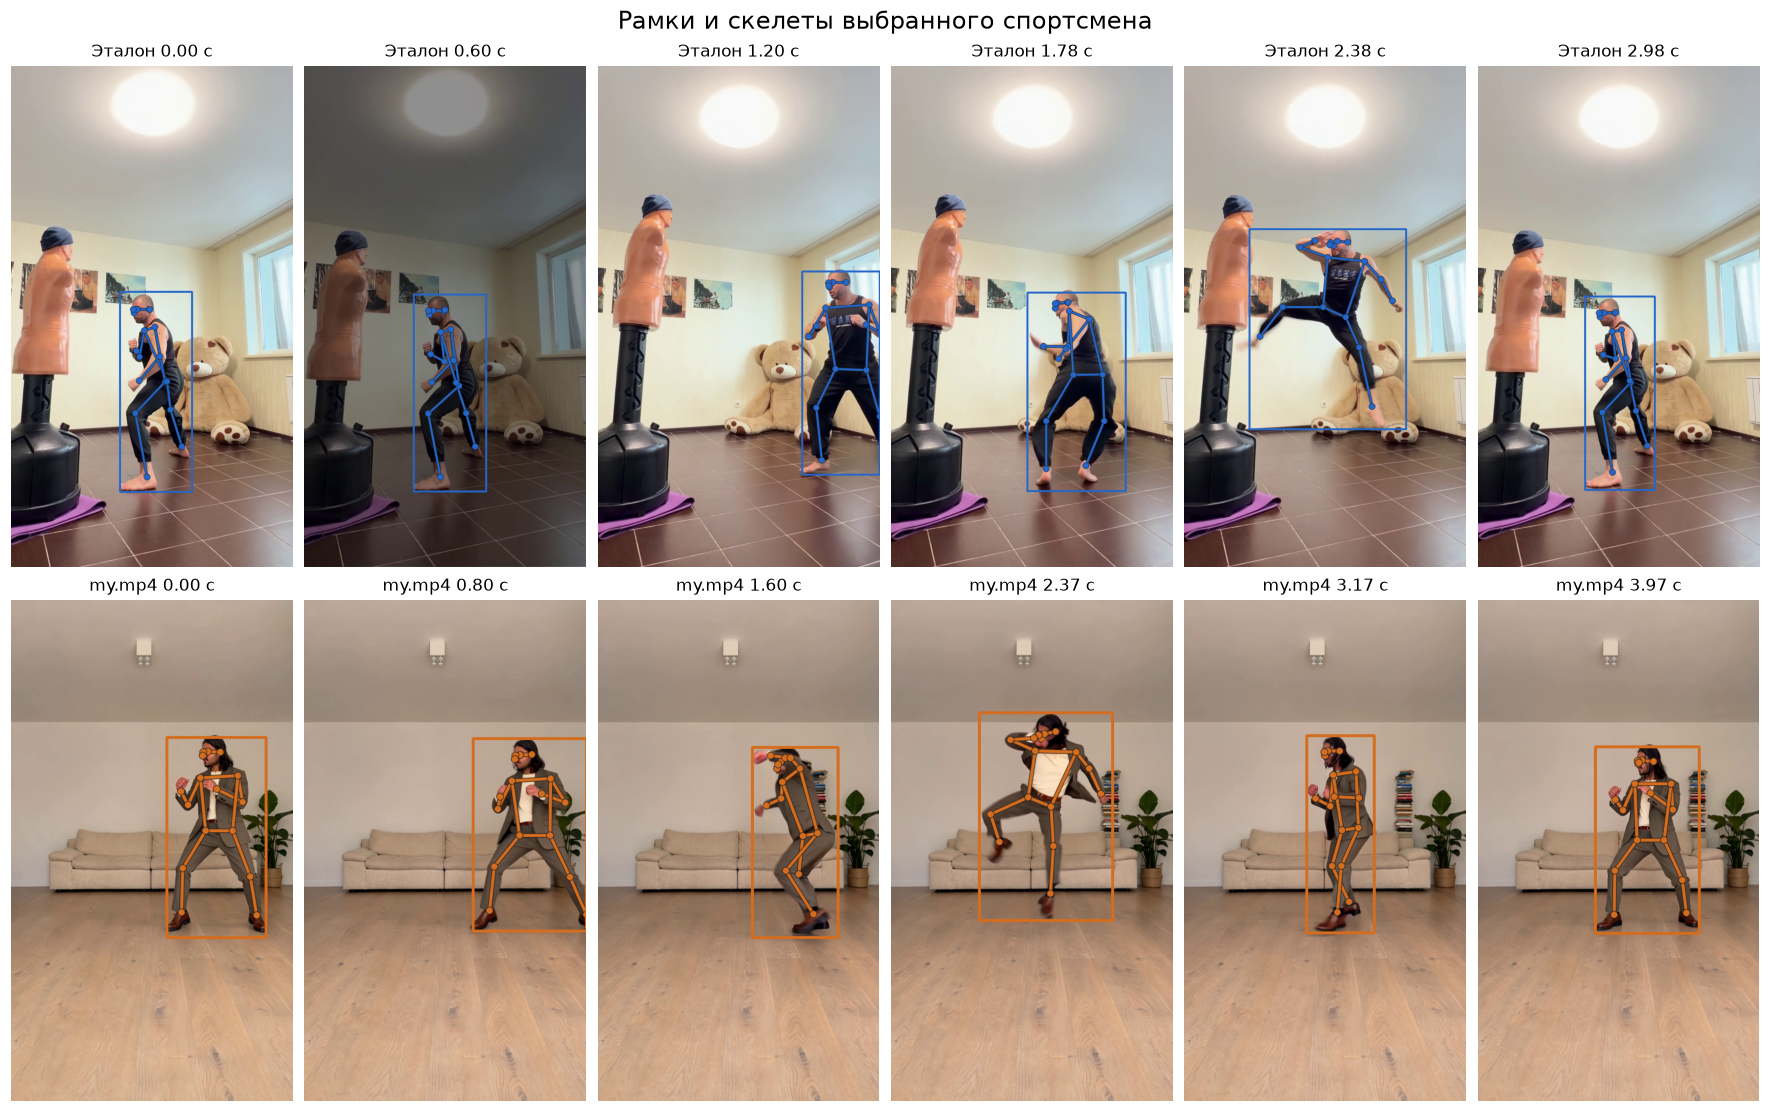

In [7]:
def draw_pose(image, pose, frame_id, color):
    result = image.copy()
    points = pose["points"][frame_id]
    scores = pose["point_scores"][frame_id]
    visible = (scores > KEYPOINT_THRESHOLD) & np.isfinite(points).all(axis=1)
    width = max(2, round(image.shape[0] / 300))
    radius = max(3, round(image.shape[0] / 180))
    for a, b in limbs:
        if visible[a] and visible[b]:
            start, end = [tuple(np.rint(point).astype(int).tolist()) for point in points[[a, b]]]
            cv2.line(result, start, end, (25, 25, 25), width + 2, cv2.LINE_AA)
            cv2.line(result, start, end, color, width, cv2.LINE_AA)
    for point in points[visible]:
        position = tuple(np.rint(point).astype(int).tolist())
        cv2.circle(result, position, radius + 1, (25, 25, 25), -1, cv2.LINE_AA)
        cv2.circle(result, position, radius, color, -1, cv2.LINE_AA)
    return result


reference_color = (36, 103, 200)
input_color = (212, 109, 31)
fig, axes = plt.subplots(2, 6, figsize=(16, 10), constrained_layout=True)
for row, (frames, times, pose, color, label) in enumerate([
    (reference_frames, reference_times, reference_pose, reference_color, 'Эталон'),
    (input_frames, input_times, input_pose, input_color, 'my.mp4'),
]):
    selected = np.rint(np.linspace(0, len(frames) - 1, 6)).astype(int)
    for col, frame_id in enumerate(selected):
        picture = draw_pose(frames[frame_id], pose, frame_id, color)
        box = pose['boxes'][frame_id]
        if np.isfinite(box).all():
            x1, y1, x2, y2 = np.rint(box).astype(int)
            cv2.rectangle(picture, (x1, y1), (x2, y2), color, 3)
        axes[row, col].imshow(picture)
        axes[row, col].set_title(f'{label} {times[frame_id]:.2f} с', fontsize=11)
        axes[row, col].axis('off')
fig.suptitle('Рамки и скелеты выбранного спортсмена', fontsize=16)
fig.savefig(OUTPUT_DIR / 'sampled_skeletons.png', dpi=140, bbox_inches='tight')
plt.show()

## 4. Совмещение и расчёт метрик

Сохраняем метод предыдущих спринтов: для каждой пары по общим надёжным точкам
подбираем полное аффинное преобразование `pad(my) @ A ≈ pad(reference)`.
Оно допускает сдвиг, поворот, разный масштаб осей, сдвиг формы и отражение.
Поэтому это **остаточная ошибка после подгонки**, а не независимая оценка точности.
Число отражений сохраняется и выводится в заключении.

Пусть $r$ — развёрнутые координаты референса, $p$ — совмещённые координаты повторения:

$$s_{cos} = \frac{r^T p}{\|r\|\,\|p\|}, \qquad d_{cos} = 1-s_{cos}.$$

**Косинусное расстояние** лежит в $[0,2]$, меньше — ближе. Для преемственности также
показываем сходство $s_{cos}$. Большие координаты относительно начала изображения
могут давать высокий косинус даже при заметном различии поз. Поэтому отдельно
вычисляем расстояние после вычитания центра каждой позы.

$$d_w = \frac{\sum_i w_i (|r_{ix}-p_{ix}| + |r_{iy}-p_{iy}|)}{\sum_i w_i}.$$

Вес $w_i$ — score соответствующей точки `my.mp4`, как в спринте II. Все веса
положительны после фильтра. **Взвешенное L1** измеряется в пикселях исходного
референса **720 × 1280**. Дополнительно делим его на фиксированную медианную высоту
рамки спортсмена в референсе. Метрики не переводятся в процент «правильности» удара.

In [8]:
def pad(points):
    points = np.asarray(points, dtype=np.float64)
    if points.ndim != 2 or points.shape[1] != 2 or not np.isfinite(points).all():
        raise ValueError("Ожидается конечный массив координат формы (N, 2).")
    return np.hstack([points, np.ones((len(points), 1))])


def unpad(points):
    return np.asarray(points)[:, :2]


def fit_affine(input_points, reference_points):
    if np.shape(input_points) != np.shape(reference_points):
        raise ValueError("Наборы должны содержать одинаковое число соответствующих точек.")
    X = pad(input_points)
    Y = pad(reference_points)
    A, residuals, rank, singular_values = np.linalg.lstsq(X, Y, rcond=None)
    if rank < 3:
        raise ValueError("Точки вырождены: аффинное преобразование не определено однозначно.")
    A[np.abs(A) < 1e-10] = 0
    assert np.allclose(A[:, 2], [0, 0, 1], atol=1e-8)
    A[:, 2] = [0, 0, 1]
    return A, int(rank)


def cosine_similarity(pose1, pose2):
    first = np.asarray(pose1, dtype=np.float64).reshape(-1)
    second = np.asarray(pose2, dtype=np.float64).reshape(-1)
    if first.shape != second.shape or first.size == 0:
        raise ValueError("Нужны непустые векторы одинакового размера.")
    if not (np.isfinite(first).all() and np.isfinite(second).all()):
        raise ValueError("Координаты должны быть конечными.")
    denominator = np.linalg.norm(first) * np.linalg.norm(second)
    if denominator <= np.finfo(float).eps:
        raise ValueError("Косинусное сходство не определено для нулевого вектора.")
    return float(np.clip(np.dot(first, second) / denominator, -1, 1))


def weight_distance(pose1, pose2, conf1):
    first = np.asarray(pose1, dtype=np.float64).reshape(-1, 2)
    second = np.asarray(pose2, dtype=np.float64).reshape(-1, 2)
    confidences = np.asarray(conf1, dtype=np.float64)
    if first.shape != second.shape or confidences.shape != (len(first),):
        raise ValueError("Одному суставу должны соответствовать две координаты и один вес.")
    if not all(np.isfinite(x).all() for x in (first, second, confidences)):
        raise ValueError("Входы должны быть конечными.")
    if np.any(confidences < 0) or confidences.sum() <= 0:
        raise ValueError("Веса должны быть неотрицательными с положительной суммой.")
    per_point_l1 = np.abs(first - second).sum(axis=1)
    return float(np.dot(confidences, per_point_l1) / confidences.sum())

In [9]:
reference_scale = float(np.nanmedian(reference_pose['boxes'][:, 3] - reference_pose['boxes'][:, 1]))
if not np.isfinite(reference_scale) or reference_scale <= 0:
    raise ValueError('Нет пригодных рамок человека в референсе')
metric_names = ['cosine_distance', 'weighted_l1_px', 'cosine_similarity',
                'centered_cosine_distance', 'normalized_l1']


def compare_pairs(pairing):
    count = len(pairing['x'])
    masks = np.zeros((count, 17), dtype=bool)
    matrices = np.full((count, 3, 3), np.nan)
    aligned = np.full((count, 17, 2), np.nan)
    errors = np.full((count, 17), np.nan)
    records = []
    for i, (ref_id, my_id) in enumerate(zip(pairing['reference_ids'], pairing['input_ids'])):
        ref_points = reference_pose['points'][ref_id]
        my_points = input_pose['points'][my_id]
        mask = ((reference_pose['point_scores'][ref_id] > KEYPOINT_THRESHOLD)
                & (input_pose['point_scores'][my_id] > KEYPOINT_THRESHOLD)
                & np.isfinite(ref_points).all(axis=1) & np.isfinite(my_points).all(axis=1))
        masks[i] = mask
        row = {'pair_index': i, 'pair_coordinate': float(pairing['x'][i]),
               'reference_frame_id': int(ref_id), 'input_frame_id': int(my_id),
               'reference_time_s': float(reference_times[ref_id]),
               'input_time_s': float(input_times[my_id]),
               'common_keypoints': int(mask.sum()), 'status': 'ok', 'reason': '',
               **{name: np.nan for name in metric_names},
               'affine_determinant': np.nan, 'affine_scale_ratio': np.nan}
        if reference_pose['person_ids'][ref_id] < 0 or input_pose['person_ids'][my_id] < 0:
            row.update(status='missing_person', reason='Нет детекции спортсмена')
        elif mask.sum() < MIN_COMMON_KEYPOINTS:
            row.update(status='insufficient_points', reason='Недостаточно общих точек')
        else:
            try:
                A, _ = fit_affine(my_points[mask], ref_points[mask])
                finite = np.isfinite(my_points).all(axis=1)
                transformed = np.full((17, 2), np.nan)
                transformed[finite] = unpad(pad(my_points[finite]) @ A)
                r, p = ref_points[mask], transformed[mask]
                similarity = cosine_similarity(r, p)
                centered = cosine_similarity(r - r.mean(axis=0), p - p.mean(axis=0))
                distance = weight_distance(r, p, input_pose['point_scores'][my_id, mask])
                scales = np.linalg.svd(A[:2, :2], compute_uv=False)
                row.update(cosine_distance=1-similarity, cosine_similarity=similarity,
                           weighted_l1_px=distance, centered_cosine_distance=1-centered,
                           normalized_l1=distance/reference_scale,
                           affine_determinant=float(np.linalg.det(A[:2, :2])),
                           affine_scale_ratio=float(scales[0]/max(scales[1], np.finfo(float).eps)))
                matrices[i], aligned[i] = A, transformed
                errors[i, mask] = np.linalg.norm(r - p, axis=1)
            except (ValueError, np.linalg.LinAlgError) as error:
                row.update(status='invalid_geometry', reason=str(error))
        records.append(row)
    valid = np.asarray([r['status'] == 'ok' for r in records])
    if not valid.any():
        raise ValueError('Нет пригодных пар: проверьте детекции и пороги')
    values = {name: np.asarray([r[name] for r in records]) for name in metric_names}
    summary = {name: {'mean': float(np.mean(v[valid])), 'median': float(np.median(v[valid])),
                     'min': float(np.min(v[valid])), 'max': float(np.max(v[valid]))}
               for name, v in values.items()}
    return {'records': records, 'valid': valid, 'masks': masks, 'matrices': matrices,
            'aligned': aligned, 'joint_l2': errors, 'values': values, 'summary': summary}


results = {mode: compare_pairs(pairing) for mode, pairing in pairings.items()}
main = results['relative']
records, summary = main['records'], main['summary']
valid_ids = np.flatnonzero(main['valid'])
joint_l2 = main['joint_l2']
print(f'Масштаб: медианная высота рамки референса {reference_scale:.1f} px')
for mode, result in results.items():
    print(f"{mode_labels[mode]}: {result['valid'].sum()}/{len(result['valid'])} пригодных пар")

Масштаб: медианная высота рамки референса 509.4 px
Полные ролики: относительное время: 120/120 пригодных пар
Первые 3 с: без изменения темпа: 90/90 пригодных пар


### Проверка расчётов

Проверяем известные значения метрик, тождественное совмещение, диапазоны,
пропуски и независимое суммирование взвешенной ошибки для одной реальной пары.
Это проверка реализации, а не оценка точности нейросети по ручной разметке.

In [10]:
assert np.isclose(1 - cosine_similarity([1, 0], [0, 1]), 1)
assert np.isclose(1 - cosine_similarity([1, 2], [2, 4]), 0)
assert np.isclose(weight_distance([[0, 0], [0, 0]], [[1, 2], [3, 4]], [1, 3]), 6)
assert np.isclose(weight_distance([[0, 0], [0, 0]], [[1, 2], [3, 4]], [10, 30]), 6)
for mode, result in results.items():
    v = result['valid']
    assert np.all((result['values']['cosine_distance'][v] >= 0)
                  & (result['values']['cosine_distance'][v] <= 2))
    assert np.all(result['values']['weighted_l1_px'][v] >= 0)
    assert np.all(np.isnan(result['values']['weighted_l1_px'][~v]))
    assert np.allclose(result['values']['cosine_distance'][v],
                       1 - result['values']['cosine_similarity'][v])
    i = int(np.flatnonzero(v)[0])
    row, mask = result['records'][i], result['masks'][i]
    points = reference_pose['points'][row['reference_frame_id'], mask]
    weights_i = input_pose['point_scores'][row['input_frame_id'], mask]
    A, _ = fit_affine(points, points)
    assert np.allclose(A, np.eye(3), atol=1e-8)
    manual = sum(float(w)*(abs(a[0]-b[0])+abs(a[1]-b[1]))
                 for a,b,w in zip(points, result['aligned'][i,mask], weights_i))/sum(weights_i)
    assert np.isclose(manual, row['weighted_l1_px'])
print('Проверки метрик и временных сопоставлений пройдены.')

Проверки метрик и временных сопоставлений пройдены.


## 5. Результаты

Среднее считается по пригодным парам равномерной сетки выбранного режима.
Кадры зависимы во времени; минимум и максимум — наблюдаемый диапазон, не доверительный
интервал. Два режима имеют разный охват и смысл: основная оценка учитывает полный
ролик при нормализации времени, контрольная — только общее начало в исходном темпе.

In [11]:
labels = {'cosine_distance': 'Косинусное расстояние ↓',
          'weighted_l1_px': 'Взвешенное L1, px ↓',
          'cosine_similarity': 'Косинусное сходство ↑',
          'centered_cosine_distance': 'Центрированное косинусное расстояние ↓',
          'normalized_l1': 'L1 / медианная высота рамки ↓'}
rows = ['| Метрика: полные ролики | Среднее | Медиана | Минимум | Максимум |',
        '| :--- | ---: | ---: | ---: | ---: |']
for name in metric_names:
    digits = 3 if name == 'weighted_l1_px' else 6
    vals = [f"{summary[name][stat]:.{digits}f}" for stat in ('mean','median','min','max')]
    rows.append('| ' + labels[name] + ' | ' + ' | '.join(vals) + ' |')
display(Markdown('\n'.join(rows)))
rows = ['| Временное сопоставление | Пригодные пары | Среднее d_cos | Среднее L1, px |',
        '| :--- | ---: | ---: | ---: |']
for mode, result in results.items():
    s = result['summary']
    rows.append(f"| {mode_labels[mode]} | {result['valid'].sum()}/{len(result['valid'])} | "
                f"{s['cosine_distance']['mean']:.6f} | {s['weighted_l1_px']['mean']:.3f} |")
display(Markdown('\n'.join(rows)))
print('Общих надёжных точек в основной оценке:',
      main['masks'][main['valid']].sum(axis=1).min(), '–', main['masks'][main['valid']].sum(axis=1).max())

| Метрика: полные ролики | Среднее | Медиана | Минимум | Максимум |
| :--- | ---: | ---: | ---: | ---: |
| Косинусное расстояние ↓ | 0.001987 | 0.001148 | 0.000029 | 0.010442 |
| Взвешенное L1, px ↓ | 51.357 | 45.949 | 7.690 | 106.284 |
| Косинусное сходство ↑ | 0.998013 | 0.998852 | 0.989558 | 0.999971 |
| Центрированное косинусное расстояние ↓ | 0.069395 | 0.049128 | 0.001187 | 0.332211 |
| L1 / медианная высота рамки ↓ | 0.100819 | 0.090203 | 0.015096 | 0.208647 |

| Временное сопоставление | Пригодные пары | Среднее d_cos | Среднее L1, px |
| :--- | ---: | ---: | ---: |
| Полные ролики: относительное время | 120/120 | 0.001987 | 51.357 |
| Первые 3 с: без изменения темпа | 90/90 | 0.000861 | 30.438 |

Общих надёжных точек в основной оценке: 12 – 17


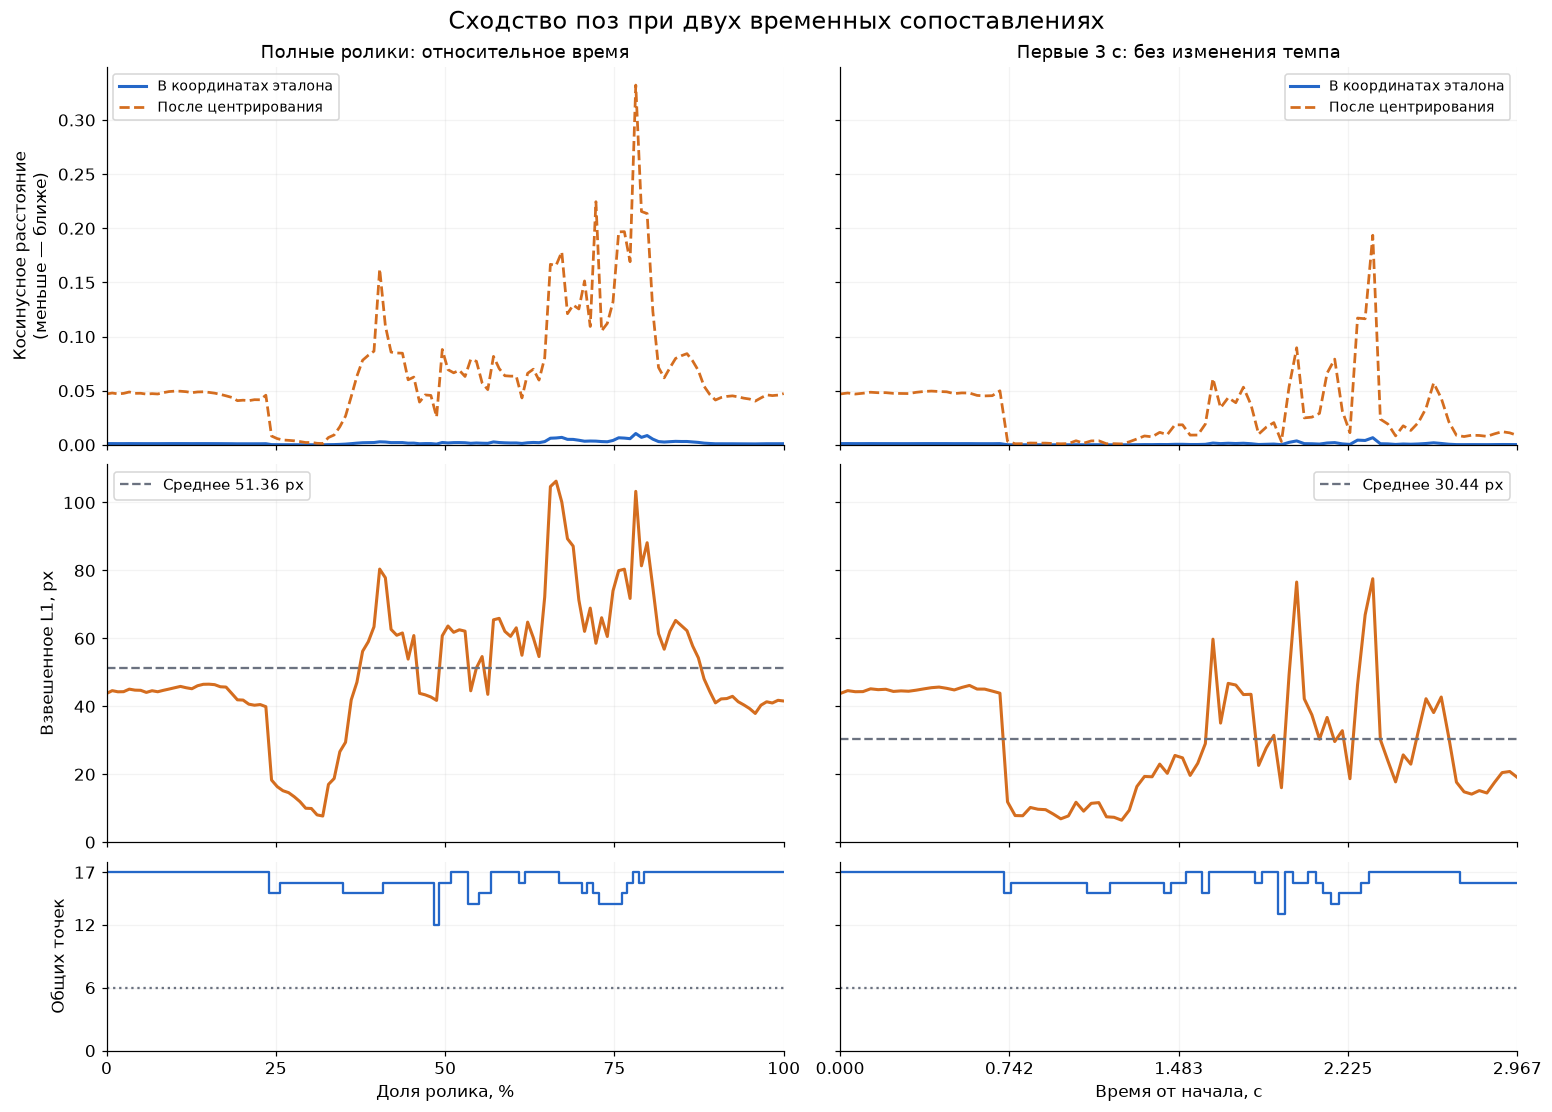

In [12]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10), constrained_layout=True,
                         gridspec_kw={'height_ratios': [2, 2, 1]}, sharex='col', sharey='row')
for col, mode in enumerate(('relative', 'realtime')):
    result, x = results[mode], pairings[mode]['x']
    values = result['values']
    axes[0, col].plot(x, values['cosine_distance'], color=COLORS['reference'], linewidth=2,
                      label='В координатах эталона')
    axes[0, col].plot(x, values['centered_cosine_distance'], color=COLORS['input'], linewidth=1.8,
                      linestyle='--', label='После центрирования')
    axes[0, col].set_title(mode_labels[mode], fontsize=12)
    axes[0, col].set_ylim(bottom=0)
    axes[0, col].legend(fontsize=9)
    axes[1, col].plot(x, values['weighted_l1_px'], color=COLORS['input'], linewidth=2)
    mean = result['summary']['weighted_l1_px']['mean']
    axes[1, col].axhline(mean, color=COLORS['neutral'], linestyle='--', label=f'Среднее {mean:.2f} px')
    axes[1, col].legend(fontsize=10)
    axes[1, col].set_ylim(bottom=0)
    axes[2, col].step(x, result['masks'].sum(axis=1), where='mid', color=COLORS['reference'])
    axes[2, col].axhline(MIN_COMMON_KEYPOINTS, color=COLORS['neutral'], linestyle=':')
    axes[2, col].set_ylim(0,18)
    axes[2, col].set_yticks([0,6,12,17])
    axes[2, col].set_xlim(x[0], x[-1])
    axes[2, col].set_xticks(np.linspace(x[0], x[-1], 5))
    axes[2, col].set_xlabel('Доля ролика, %' if mode == 'relative' else 'Время от начала, с')
    for ax in axes[:, col]:
        ax.grid(alpha=0.15)
axes[0,0].set_ylabel('Косинусное расстояние\n(меньше — ближе)')
axes[1,0].set_ylabel('Взвешенное L1, px')
axes[2,0].set_ylabel('Общих точек')
fig.suptitle('Сходство поз при двух временных сопоставлениях', fontsize=16)
fig.savefig(OUTPUT_DIR / 'metrics_comparison.png', dpi=140, bbox_inches='tight')
plt.show()

### Где различия выражены сильнее

Ниже показано среднее **L2-отклонение** каждого сустава после аффинного совмещения
в основном режиме. Это диагностическая метрика, а не взвешенное L1. У каждой точки
свой знаменатель `n`: учитываются только пары, где она надёжно найдена в обоих роликах.

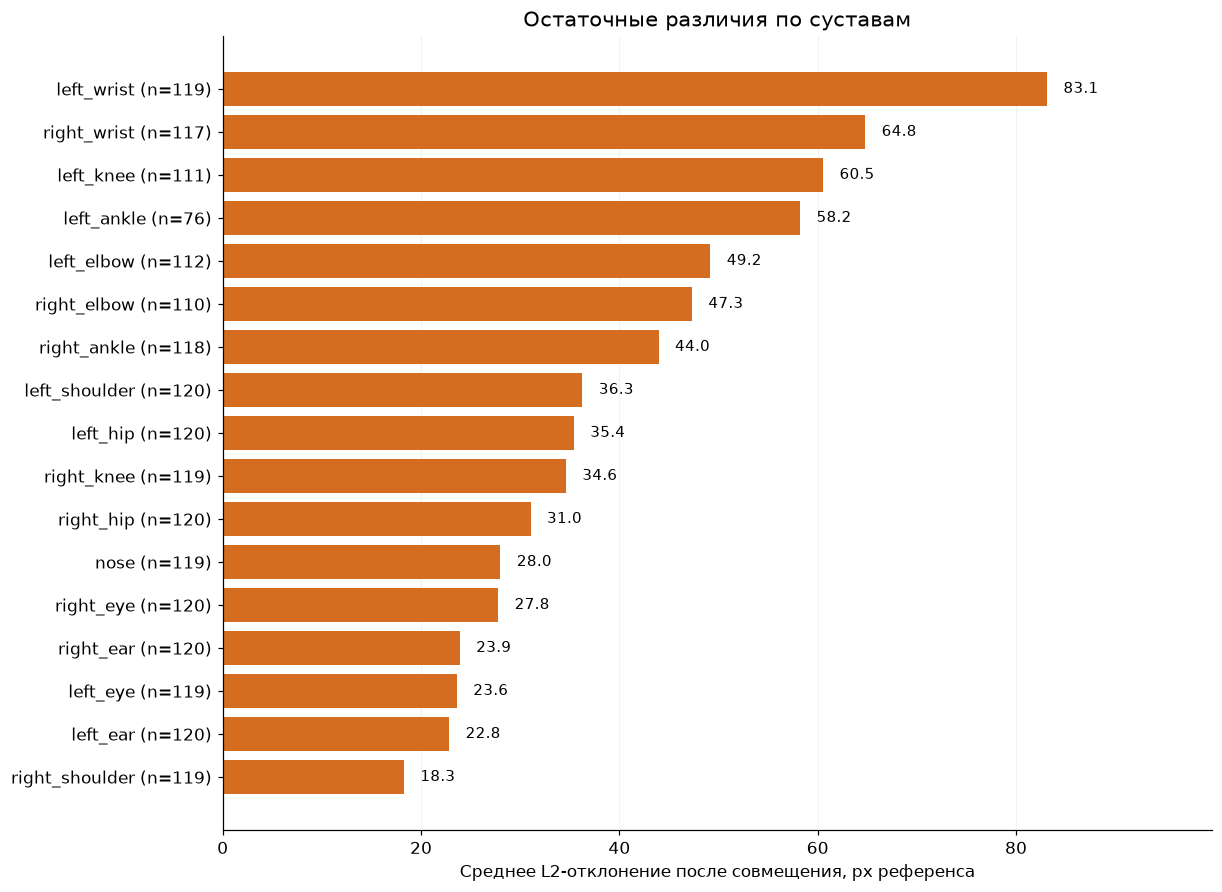

In [13]:
joint_counts = np.isfinite(joint_l2).sum(axis=0)
joint_means = np.divide(np.nansum(joint_l2, axis=0), joint_counts,
                        out=np.full(17, np.nan), where=joint_counts > 0)
joint_order = np.asarray(sorted(np.flatnonzero(joint_counts > 0), key=lambda i: joint_means[i], reverse=True))
fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
joint_labels = [f"{keypoints[i]} (n={joint_counts[i]})" for i in joint_order]
ax.barh(joint_labels, joint_means[joint_order], color=COLORS["input"])
ax.invert_yaxis()
max_error = float(np.max(joint_means[joint_order]))
ax.set_xlim(0, max(1.0, max_error * 1.2))
for rank_id, joint_id in enumerate(joint_order):
    ax.text(joint_means[joint_id] + max_error * 0.02, rank_id,
            f"{joint_means[joint_id]:.1f}", va="center", fontsize=10)
ax.set_xlabel("Среднее L2-отклонение после совмещения, px референса")
ax.set_title("Остаточные различия по суставам")
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.savefig(OUTPUT_DIR / "joint_errors.png", dpi=150, bbox_inches="tight")
plt.show()

### Наложение поз в паре с наибольшим L1

Показываем референс, совмещённое повторение и отрезки остаточной ошибки.
Это помогает отличить визуально заметные различия от высокого косинусного сходства.

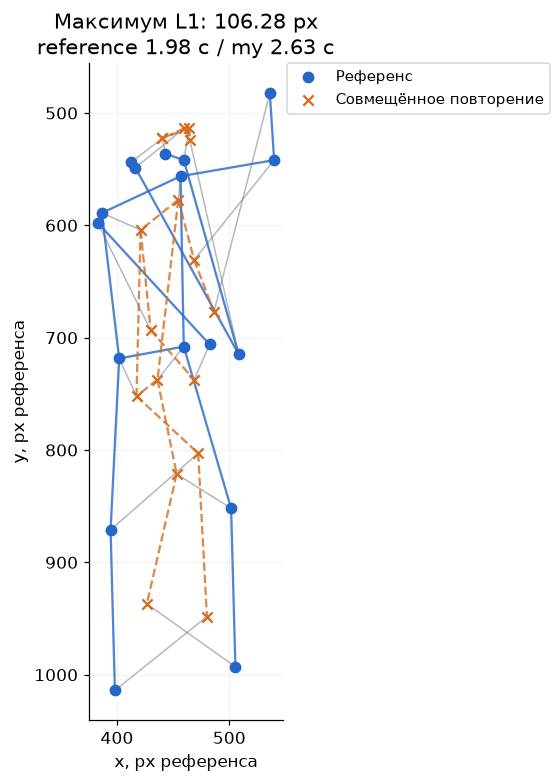

In [14]:
worst_id = int(valid_ids[np.argmax(main['values']['weighted_l1_px'][main['valid']])])
best_id = int(valid_ids[np.argmin(main['values']['weighted_l1_px'][main['valid']])])
row = records[worst_id]
mask = main['masks'][worst_id]
r = reference_pose['points'][row['reference_frame_id']]
p = main['aligned'][worst_id]
fig, ax = plt.subplots(figsize=(7,7), constrained_layout=True)
for points, color, marker, linestyle, label in [
    (r, COLORS['reference'], 'o', '-', 'Референс'),
    (p, COLORS['input'], 'x', '--', 'Совмещённое повторение'),
]:
    for a,b in limbs:
        if mask[a] and mask[b]:
            ax.plot(points[[a,b],0], points[[a,b],1], color=color, linestyle=linestyle, alpha=.8)
    ax.scatter(points[mask,0],points[mask,1],color=color,marker=marker,s=45,label=label,zorder=3)
for a,b in zip(r[mask],p[mask]):
    ax.plot([a[0],b[0]],[a[1],b[1]],color=COLORS['neutral'],alpha=.5,linewidth=1)
ax.set_aspect('equal')
ax.invert_yaxis()
ax.set_xlabel('x, px референса'); ax.set_ylabel('y, px референса')
ax.set_title(f"Максимум L1: {row['weighted_l1_px']:.2f} px\n"
             f"reference {row['reference_time_s']:.2f} с / my {row['input_time_s']:.2f} с")
ax.legend(fontsize=10, loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
ax.grid(alpha=.15)
fig.savefig(OUTPUT_DIR / 'worst_pose_alignment.png', dpi=140, bbox_inches='tight')
plt.show()

## 6. Видео с оценкой и скелетами

Основной ролик показывает **120 пар за 4 с** при 30 FPS. Референс растянут до
длительности повторения; реальные времена источников указаны сверху.
Полоса внизу показывает расстояния текущей пары. Скелеты остаются в исходных координатах.
Второй ролик — сравнение первых 3 с в исходном темпе. Оба MP4 сохранены в H.264 без звука.

In [15]:
font_path = font_manager.findfont('DejaVu Sans')
video_font = ImageFont.truetype(font_path, 17)
small_font = ImageFont.truetype(font_path, 16)


def make_comparison_frame(mode, i):
    row = results[mode]['records'][i]
    ref_id, my_id = row['reference_frame_id'], row['input_frame_id']
    canvas = Image.new('RGB', (720, 800), (248,250,252))
    draw = ImageDraw.Draw(canvas)
    for offset, frames, pose, frame_id, color in [
        (0, reference_frames, reference_pose, ref_id, reference_color),
        (360, input_frames, input_pose, my_id, input_color),
    ]:
        picture = Image.fromarray(draw_pose(frames[frame_id],pose,frame_id,color))
        picture.thumbnail((360,640), Image.Resampling.LANCZOS)
        canvas.paste(picture,(offset+(360-picture.width)//2,48+(640-picture.height)//2))
    draw.text((12,14),f"Эталон · {row['reference_time_s']:.3f} с",font=video_font,fill=reference_color)
    draw.text((372,14),f"my.mp4 · {row['input_time_s']:.3f} с",font=video_font,fill=input_color)
    if row['status'] == 'ok':
        text = f"d_cos: {row['cosine_distance']:.5f}   |   L1: {row['weighted_l1_px']:.2f} px   |   меньше — ближе"
    else:
        text = f"Нет оценки: {row['status']}"
    draw.text((12,700),text,font=video_font,fill=(25,35,50))
    draw.text((12,734),mode_labels[mode],font=small_font,fill=(60,65,75))
    draw.text((12,768),f"Общих точек: {row['common_keypoints']}/17 · 2D-сходство после совмещения",
              font=small_font,fill=(60,65,75))
    return np.asarray(canvas)


def save_video(mode, name, fps):
    executable = shutil.which('ffmpeg')
    if executable is None:
        raise RuntimeError('FFmpeg не найден. Установите FFmpeg и добавьте его в PATH.')
    path = OUTPUT_DIR / name
    temporary = path.with_name(path.stem + '_pending.mp4')
    log_path = OUTPUT_DIR / f'ffmpeg_{mode}.log'
    command = [executable,'-y','-loglevel','error','-f','rawvideo','-pix_fmt','rgb24',
               '-s','720x800','-r',str(fps),'-i','pipe:0','-an','-c:v','libx264',
               '-preset','fast','-crf','20','-pix_fmt','yuv420p','-movflags','+faststart',str(temporary)]
    with log_path.open('wb') as log:
        process = subprocess.Popen(command,stdin=subprocess.PIPE,stdout=subprocess.DEVNULL,stderr=log,
                                   creationflags=getattr(subprocess,'CREATE_NO_WINDOW',0))
        try:
            for i in range(len(results[mode]['records'])):
                process.stdin.write(make_comparison_frame(mode,i).tobytes())
            process.stdin.close()
            return_code = process.wait(timeout=120)
        except Exception:
            process.kill(); process.wait()
            raise
    if return_code:
        raise RuntimeError(log_path.read_text(encoding='utf-8',errors='replace'))
    meta = video_metadata(temporary)
    assert meta['frame_count'] == len(results[mode]['records']) and np.isclose(meta['fps'],fps)
    temporary.replace(path)
    return path


comparison_path = save_video('relative','movement_comparison.mp4',ANALYSIS_FPS)
realtime_path = save_video('realtime','movement_realtime.mp4',realtime_fps)
display(Video(str(comparison_path),embed=True,width=720,html_attributes='controls muted loop playsinline'))

### Контрольное видео без изменения темпа

Здесь сравниваются одинаковые секунды от начала записей, только общий интервал.
Различие оценок между режимами отражает в том числе влияние временного сопоставления.

In [16]:
display(Video(str(realtime_path),embed=True,width=720,html_attributes='controls muted loop playsinline'))

## 7. Сохранение результатов

В `outputs/` сохраняются покадровые метрики обоих режимов (с причинами пропусков),
диагностика детекций, средние ошибки суставов, исходные предсказания и матрицы
совмещения, графики и оба MP4. `comparison_results.json` содержит настройки,
определения метрик, версии библиотек и SHA-256 исходных файлов. Числа в файлах
не округляются; округление в таблицах предназначено только для чтения.

In [17]:
def write_csv(path, rows):
    with path.open("w", encoding="utf-8-sig", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=rows[0].keys())
        writer.writeheader()
        for row in rows:
            writer.writerow({key: "" if isinstance(value, (float, np.floating)) and not np.isfinite(value)
                             else value for key, value in row.items()})


for mode, result in results.items():
    write_csv(OUTPUT_DIR / f'frame_metrics_{mode}.csv', result['records'])
write_csv(OUTPUT_DIR / 'joint_summary.csv', [
    {'keypoint':name,'valid_pairs':int(joint_counts[i]),'mean_l2_reference_px':float(joint_means[i])}
    for i,name in enumerate(keypoints)])
detection_rows = []
for source, pose, times in [('reference',reference_pose,reference_times),('input',input_pose,input_times)]:
    for i,t in enumerate(times):
        detection_rows.append({'source':source,'frame_id':i,'time_s':float(t),
                               'detection_index':int(pose['person_ids'][i]),
                               'person_score':float(pose['person_scores'][i]),
                               'candidates':int(pose['candidate_counts'][i]),
                               'eligible_candidates':int(pose['eligible_counts'][i]),
                               'reliable_keypoints':int((pose['point_scores'][i]>KEYPOINT_THRESHOLD).sum())})
write_csv(OUTPUT_DIR / 'detection_diagnostics.csv',detection_rows)
saved_arrays = dict(prediction_arrays)
saved_arrays.update(reference_times=reference_times,input_times=input_times,
                    keypoint_names=np.asarray(keypoints),limbs=np.asarray(limbs))
for mode, result in results.items():
    for name in ('valid','masks','matrices','aligned','joint_l2'):
        saved_arrays[f'{mode}_{name}'] = result[name]
    for name,value in pairings[mode].items():
        saved_arrays[f'{mode}_{name}'] = value
np.savez_compressed(OUTPUT_DIR / 'video_pose_comparison.npz', **saved_arrays)
run_info = {
    'application':'martial arts: comparison of a repeated kick',
    'input_sha256':source_hashes,'reference_video':reference_meta,'input_video':input_meta,
    'assignment_files':['Course _ Skillfactory_1.mhtml','Course _ Skillfactory_2.mhtml','другие модели.mhtml'],
    'model':'keypointrcnn_resnet50_fpn','weights':weights.name,'weights_url':weights.url,
    'versions':versions,'device':str(DEVICE),'cache_schema':CACHE_SCHEMA,
    'conf_threshold':CONF_THRESHOLD,'keypoint_threshold':KEYPOINT_THRESHOLD,
    'min_common_keypoints':MIN_COMMON_KEYPOINTS,'selection_x_range':SELECTION_X_RANGE,
    'spatial_alignment':'full affine least squares on shared reliable joints; reflection allowed',
    'cosine_distance_definition':'1 - dot(flatten(reference), flatten(aligned_input))/(norm(reference)*norm(aligned_input))',
    'weighted_l1_definition':'sum(input_joint_score*(abs(dx)+abs(dy)))/sum(input_joint_score)',
    'aggregation':'unweighted mean over valid pairs in each specified pairing',
    'reference_scale_median_bbox_height_px':reference_scale,
    'temporal_alignment':{
        'relative':'uniform progress from first to last actual frame of each full clip; nearest frame; no DTW',
        'realtime':'same elapsed time on common [0,min(duration)) interval; no offset search',
    },
    'results':{mode:{'pair_count':len(r['records']),'valid_pair_count':int(r['valid'].sum()),
                     'metrics':r['summary'],
                     'reflected_affine_pairs':sum(row['affine_determinant'] < 0 for row in r['records'] if row['status']=='ok')}
               for mode,r in results.items()},
}
(OUTPUT_DIR / 'comparison_results.json').write_text(json.dumps(run_info,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
print('Результаты сохранены:',OUTPUT_DIR.relative_to(PROJECT_DIR))

Результаты сохранены: outputs


## 8. Выводы

Все числа ниже рассчитываются при выполнении ноутбука. Высокое сходство после
аффинной подгонки не означает правильной техники: преобразование может скрывать
часть различий в геометрии, а движения сняты с разных ракурсов. Без разметки фаз
линейная нормализация времени не гарантирует совпадение момента удара.

In [18]:
best, worst = records[best_id], records[worst_id]
top = '; '.join(f'{keypoints[i]} — {joint_means[i]:.1f} px (n={joint_counts[i]})' for i in joint_order[:3])
control = results['realtime']['summary']
reflections = run_info['results']['relative']['reflected_affine_pairs']
display(Markdown(
    f"**Полные ролики:** {reference_meta['duration_s']:g} с референса и {input_meta['duration_s']:g} с повторения, "
    f"{main['valid'].sum()}/{pair_count} пригодных пар.\n\n"
    f"- Среднее косинусное расстояние: **{summary['cosine_distance']['mean']:.6f}** "
    f"(сходство **{summary['cosine_similarity']['mean']:.6f}**).\n"
    f"- Среднее взвешенное L1: **{summary['weighted_l1_px']['mean']:.3f} px** референса.\n"
    f"- После центрирования косинусное расстояние: **{summary['centered_cosine_distance']['mean']:.6f}**.\n"
    f"- Без изменения темпа, в общих первых {common_duration:g} с: "
    f"**d_cos={control['cosine_distance']['mean']:.6f}**, **L1={control['weighted_l1_px']['mean']:.3f} px**.\n\n"
    f"Минимум L1 **{best['weighted_l1_px']:.2f} px** при reference {best['reference_time_s']:.2f} с / "
    f"my {best['input_time_s']:.2f} с; максимум **{worst['weighted_l1_px']:.2f} px** "
    f"при reference {worst['reference_time_s']:.2f} с / my {worst['input_time_s']:.2f} с.\n\n"
    f"Наибольшие средние остаточные отклонения суставов: {top}. "
    f"Аффинных преобразований с отражением: **{reflections}** из {len(valid_ids)}.\n\n"
    "Для просмотра различий полезны видео и наложение поз в худшей паре. "
    "Оценка не отделяет влияние ракурса, тайминга и ошибок детектора от самого движения. "
    "Покадровая метрика не измеряет силу удара, баланс или безопасность техники.\n\n"
    "**Задание спринта IV выполнено:** выбрана сфера применения, загружены и предобработаны "
    "референс и повторение, рассчитаны косинусное и взвешенное расстояния, "
    "оценки выведены вместе со скелетами в видео."
))

**Полные ролики:** 3 с референса и 4 с повторения, 120/120 пригодных пар.

- Среднее косинусное расстояние: **0.001987** (сходство **0.998013**).
- Среднее взвешенное L1: **51.357 px** референса.
- После центрирования косинусное расстояние: **0.069395**.
- Без изменения темпа, в общих первых 3 с: **d_cos=0.000861**, **L1=30.438 px**.

Минимум L1 **7.69 px** при reference 0.95 с / my 1.27 с; максимум **106.28 px** при reference 1.98 с / my 2.63 с.

Наибольшие средние остаточные отклонения суставов: left_wrist — 83.1 px (n=119); right_wrist — 64.8 px (n=117); left_knee — 60.5 px (n=111). Аффинных преобразований с отражением: **75** из 120.

Для просмотра различий полезны видео и наложение поз в худшей паре. Оценка не отделяет влияние ракурса, тайминга и ошибок детектора от самого движения. Покадровая метрика не измеряет силу удара, баланс или безопасность техники.

**Задание спринта IV выполнено:** выбрана сфера применения, загружены и предобработаны референс и повторение, рассчитаны косинусное и взвешенное расстояния, оценки выведены вместе со скелетами в видео.